# 03 - Uncertainty of the ensembles on the RAND split

**Question:** when an ensemble of MLPs is wrong, does its uncertainty say so?

For each test shape, an ensemble of $K$ networks gives a prediction $\mu$ (mean of the $K$ predictions) and an
uncertainty $\sigma$ (their standard deviation). The ensemble is **calibrated** if the true value falls in
$\mu \pm 1.645\,\sigma$ for 90 % of the shapes, and **useful** if $\sigma$ is large exactly where the error is large.

Inputs (no training here):
- `results/uq_metrics_RAND_test.csv` and `results/uq_calibration_RAND_test.csv`, written by `src/uq_metrics.py`;
- `results/baseline_RAND_<tag>_predictions.npz`, the per-network test predictions written by `src/train_baseline.py`.

Models: **paper** = our reproduction of the paper's architecture (3 × 256, no regularisation); **A** = 5 × 256,
weight decay 0.1 (reference); **B** = 6 × 256, weight decay 0.2. All have 20 networks. See
`analysis/model_selection.md` for how A and B were chosen.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RES, FIG = ROOT / "results", ROOT / "figures"
FIG.mkdir(exist_ok=True)

uq = pd.read_csv(RES / "uq_metrics_RAND_test.csv")
cal = pd.read_csv(RES / "uq_calibration_RAND_test.csv")

# one fixed colour per model, everywhere in the notebook
RUNS = {"paper": "#1baf7a", "A_final": "#2a78d6", "B_final": "#eb6834"}
LABEL = {"paper": "paper 3×256", "A_final": "A 5×256, wd 0.1", "B_final": "B 6×256, wd 0.2"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "font.size": 10, "legend.frameon": False})
print(f"{len(uq)} rows (expected 3 x 13 x 12 = 468)")
uq.groupby(["run", "K"]).agg(groups=("group", "nunique"), targets=("target", "nunique"))

468 rows (expected 3 x 13 x 12 = 468)


groups  targets
run     K                  
A_final 3        6       12
        5        4       12
        10       2       12
        20       1       12
B_final 3        6       12
        5        4       12
        10       2       12
        20       1       12
paper   3        6       12
        5        4       12
        10       2       12
        20       1       12

## 1. Summary at K = 20

Mean over the 12 targets. `z_std` is the standard deviation of $(y-\mu)/\sigma$: 1 means honest, above 1 means the
errors are larger than the ensemble admits (over-confident). `width90 × z_std` is a rough width of the 90 %
interval once $\sigma$ is rescaled to be honest (computed properly on day 6 with a calibration set).

In [2]:
cols = ["rmse", "mean_sigma", "coverage90", "coverage95", "z_std", "nll", "spearman", "miscal_area", "width90"]
k20 = uq[uq.K == 20].groupby("run")[cols].mean().loc[list(RUNS)]
k20["width90 x z_std"] = k20.width90 * k20.z_std
k20.round(3)

,rmse,mean_sigma,coverage90,coverage95,z_std,nll,spearman,miscal_area,width90,width90 x z_std
run,,,,,,,,,,
paper,0.214,0.129,0.867,0.911,1.182,-0.590,0.514,0.062,0.426,0.503
A_final,0.197,0.098,0.793,0.853,1.442,-0.595,0.521,0.080,0.324,0.467
B_final,0.198,0.082,0.705,0.775,1.804,-0.170,0.501,0.134,0.270,0.487


## 2. Calibration curves

For each nominal level $p$ (5 %, 10 %, ..., 95 %), the fraction of test shapes whose true value falls in the central
interval $\mu \pm z_p\,\sigma$. A calibrated ensemble follows the diagonal; a curve **below** it is over-confident.

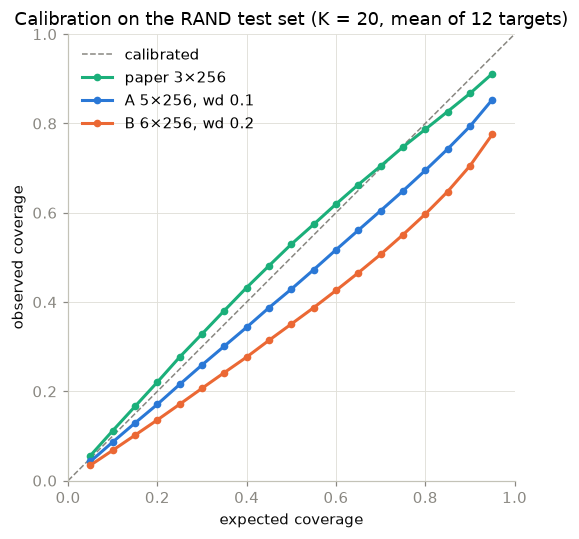

In [3]:
curve = (cal[cal.K == 20].groupby(["run", "expected"])["observed"].mean().unstack(0))[list(RUNS)]

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="calibrated")
for run, color in RUNS.items():
    ax.plot(curve.index, curve[run], color=color, lw=2, marker="o", ms=4, label=LABEL[run])
ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel="expected coverage", ylabel="observed coverage",
       title="Calibration on the RAND test set (K = 20, mean of 12 targets)")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "uq_rand_calibration.png", dpi=200, bbox_inches="tight")

## 3. Effect of the number of networks K

$K < 20$ is computed on disjoint groups of networks (6 groups of 3, 4 of 5, 2 of 10); the bars are the standard
deviation across groups, i.e. the luck of which networks were drawn.

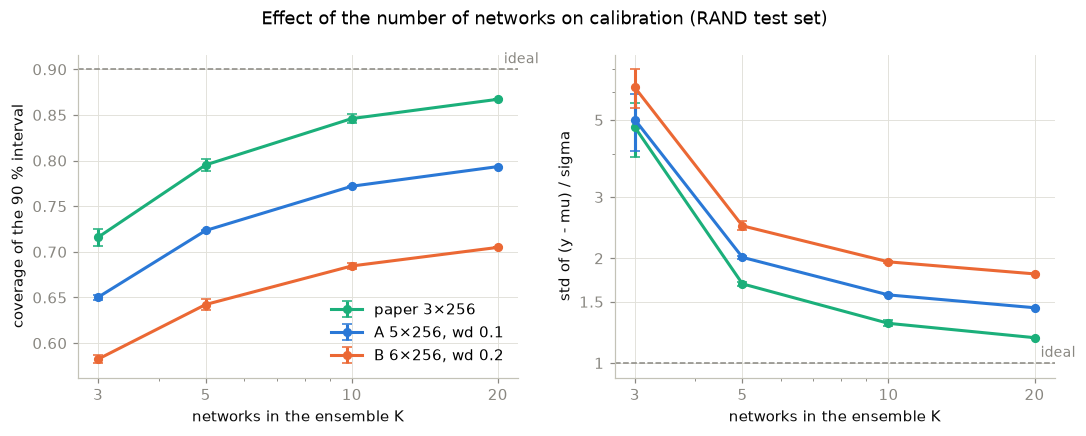

In [4]:
g = uq.groupby(["run", "K", "group"])[["coverage90", "z_std"]].mean().groupby(["run", "K"]).agg(["mean", "std"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, ideal, ylab in [(axes[0], "coverage90", 0.90, "coverage of the 90 % interval"),
                                (axes[1], "z_std", 1.0, "std of (y - mu) / sigma")]:
    ax.axhline(ideal, color=MUTED, lw=1, ls="--")
    ax.annotate("ideal", (20, ideal), xytext=(4, 4), textcoords="offset points", color=MUTED, fontsize=9)
    for run, color in RUNS.items():
        d = g.loc[run]
        ax.errorbar(d.index, d[(metric, "mean")], yerr=d[(metric, "std")].fillna(0), color=color, lw=2,
                    marker="o", ms=5, capsize=3, label=LABEL[run])
    ax.set(xscale="log", xticks=[3, 5, 10, 20], xticklabels=["3", "5", "10", "20"], xlabel="networks in the ensemble K",
           ylabel=ylab)
axes[1].set_yscale("log"); axes[1].set_yticks([1, 1.5, 2, 3, 5]); axes[1].set_yticklabels(["1", "1.5", "2", "3", "5"])
for ax in axes:
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
axes[0].legend(loc="lower right")
fig.suptitle("Effect of the number of networks on calibration (RAND test set)")
fig.tight_layout(); fig.savefig(FIG / "uq_rand_effect_of_k.png", dpi=200, bbox_inches="tight")

## 4. Calibration per target (K = 20)

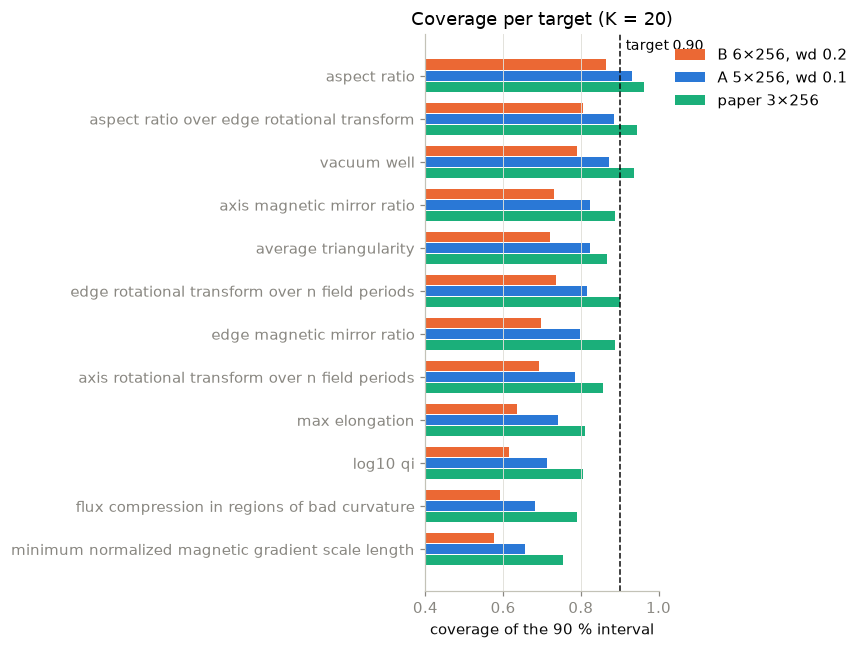

In [5]:
t = uq[uq.K == 20].pivot_table(index="target", columns="run", values="coverage90")[list(RUNS)]
t = t.sort_values("A_final")

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(t)); h = 0.26
for i, (run, color) in enumerate(RUNS.items()):
    ax.barh(y + (i - 1) * h, t[run], height=h * 0.9, color=color, label=LABEL[run])
ax.axvline(0.90, color=INK, lw=1, ls="--")
ax.annotate("target 0.90", (0.90, len(t) - 0.4), xytext=(4, 0), textcoords="offset points", fontsize=9)
ax.set(yticks=y, yticklabels=[s.replace("_", " ") for s in t.index], xlim=(0.4, 1.0),
       xlabel="coverage of the 90 % interval", title="Coverage per target (K = 20)")
ax.grid(axis="y", visible=False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(FIG / "uq_rand_coverage_per_target.png", dpi=200, bbox_inches="tight")

## 5. Does the ensemble hesitate where it errs?

Test shapes (all 12 targets pooled, z-scored) are sorted by their predicted $\sigma$ and cut into 10 bins of equal
size. For each bin: root mean square of $\sigma$ (what the ensemble announces) against RMSE (what it actually
gets wrong). Points on the diagonal are honest; points above it are over-confident. A rising curve means
$\sigma$ ranks the shapes correctly, even if its scale is off.

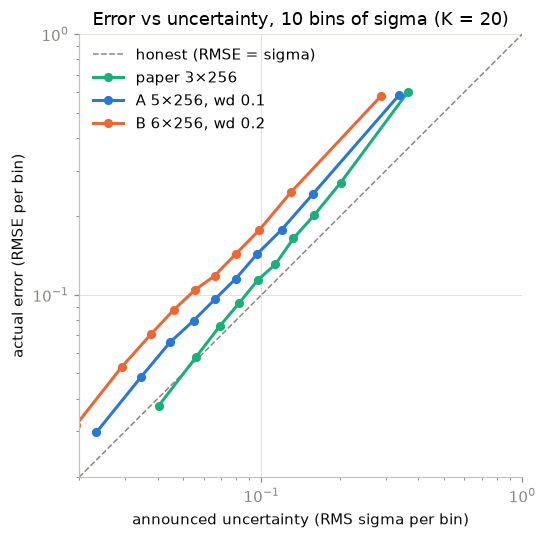

In [6]:
def binned(tag, n_bins=10):
    d = np.load(RES / f"baseline_RAND_{tag}_predictions.npz")
    P, y = d["pred_z"], d["y_true_z"]
    mu, sigma = P.mean(0).ravel(), P.std(0, ddof=1).ravel()
    err = (y.ravel() - mu)
    order = np.argsort(sigma)
    bins = np.array_split(order, n_bins)
    return (np.array([np.sqrt(np.mean(sigma[b] ** 2)) for b in bins]),
            np.array([np.sqrt(np.mean(err[b] ** 2)) for b in bins]))

fig, ax = plt.subplots(figsize=(5.2, 5))
lims = [0.02, 1.0]
ax.plot(lims, lims, color=MUTED, lw=1, ls="--", label="honest (RMSE = sigma)")
for run, color in RUNS.items():
    s, e = binned(run)
    ax.plot(s, e, color=color, lw=2, marker="o", ms=5, label=LABEL[run])
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, aspect="equal",
       xlabel="announced uncertainty (RMS sigma per bin)", ylabel="actual error (RMSE per bin)",
       title="Error vs uncertainty, 10 bins of sigma (K = 20)")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "uq_rand_error_vs_sigma.png", dpi=200, bbox_inches="tight")

## Summary

*(Numbers from the run of 9 November 2026, RAND test set, K = 20, mean over the 12 targets.)*

- **All three ensembles are over-confident.** The 90 % interval covers 87 % (paper), 79 % (A) and 70 % (B) of
  the test shapes; errors are 1.18, 1.44 and 1.80 times larger than the announced $\sigma$.
- **The more accurate models are the less honest.** From paper to A the error drops by 8 % (RMSE 0.214 → 0.197)
  but $\sigma$ drops by 24 % (0.129 → 0.098), by 36 % for B: weight decay makes the networks agree with each
  other more than it makes them right. The ensemble only sees the disagreement between networks, not the error
  they all share (the floor $a$ of `analysis/model_selection.md`, section 7.2).
- **The ranking is useful.** Spearman correlation between $\sigma$ and the error is about 0.5 for every model:
  the ensemble does hesitate more on the shapes where it errs more, its scale is just too small.
- **K matters for the uncertainty, not for the prediction.** Coverage still rises between 10 and 20 networks,
  part of it because a standard deviation over few networks is a noisy estimate. 10 networks, as in the paper,
  under-estimate the uncertainty; we keep 20.
- **The hardest targets are the worst calibrated:** gradient scale length, log10 qi, flux compression.
- **Next (day 6):** learn a correction of $\sigma$ on the validation set (scaling, conformal prediction) and check
  on the test set which model gives the narrowest *honest* intervals. Rough estimate (`width90 × z_std`): A.